**TLDR**: Reduces the ~5,000-dimensional pixel and HOG feature vectors to a small number of principal components. PCA is computed from the thin singular value decomposition of the centred training data (rather than an eigendecomposition of the covariance matrix, which squares the condition number), with a randomized SVD (Halko et al., 2011) as a faster alternative. Implemented in `src/porkqc/pca.py` and verified against scikit-learn with 7 pytest tests, on the `feature/pca` branch.

## Set-up

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

REPO_DIR = "/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection"
ZIP_PATH = "/content/drive/MyDrive/MMA3001/Pork Rasher Error-Packaging-.v4i.coco.zip"
%cd "{REPO_DIR}"

token = userdata.get("GITHUB_TOKEN")
PUSH_URL = f"https://{token}@github.com/chrixxv1/Pork-Tray-Inspection.git"

!mkdir -p /content/data
!unzip -oq "{ZIP_PATH}" -d /content/data
DATA_DIR = "/content/data"
CACHE_DIR = f"{REPO_DIR}/results/cache"   # extracted features saved on Drive, reused next session

!pip install -q -e .
import sys
sys.path.insert(0, f"{REPO_DIR}/src")
!git branch

Mounted at /content/drive
/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for porkqc (pyproject.toml) ... done
  feature/data-loader
  feature/features
* main


##Branching

In [2]:
!git switch main
!git pull {PUSH_URL} main
!git switch -c feature/pca

M	notebooks/0_setup.ipynb
M	notebooks/1_exploring_data.ipynb
M	notebooks/3_features.ipynb
Already on 'main'
Your branch is ahead of 'origin/main' by 13 commits.
  (use "git push" to publish your local commits)
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 932 bytes | 1024 bytes/s, done.
From https://github.com/chrixxv1/Pork-Tray-Inspection
 * branch            main       -> FETCH_HEAD
Updating 3f1edee..cc02bde
Fast-forward
 AI_USE_LOG.md | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
Switched to a new branch 'feature/pca'


##Add Scikit-Learn as Dependency

In [3]:
%%writefile pyproject.toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "porkqc"
version = "0.1.0"
description = "Tray-level pass/fail inspection of packaged pork rashers"
requires-python = ">=3.10"
dependencies = ["numpy", "pillow", "scikit-image", "scikit-learn"]

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]

Overwriting pyproject.toml


## PCA Module

In [4]:
%%writefile src/porkqc/pca.py
"""Principal Component Analysis computed with the thin singular value decomposition.

Given a centred data matrix ``Xc = X - mean`` of shape ``(n, d)``, the thin SVD
``Xc = U S V^T`` gives the principal directions as the rows of ``V^T`` and the
variance along each as ``S**2 / (n - 1)``.

Why SVD rather than an eigendecomposition of the covariance ``Xc^T Xc``:
forming ``Xc^T Xc`` squares the condition number of the problem, so small
singular values lose about twice as many significant digits. The SVD works on
``Xc`` directly and is backward stable (Golub & Van Loan, 2013, ch. 8).

Two solvers are provided:

* ``"full"`` - LAPACK thin SVD (``numpy.linalg.svd``). For an ``m x k`` matrix
  (``m >= k``) this costs on the order of ``m k**2`` flops, with a constant
  between about 4 and 14 depending on which factors are formed (Golub & Van
  Loan, 2013, ch. 8). Here ``k = min(n, d) = 3349``, so all ~3349 components
  are computed even though only a few hundred are kept.
* ``"randomized"`` - the randomized range finder of Halko, Martinsson & Tropp
  (2011). It computes only the leading ``r = n_components + oversample``
  components at a cost of order ``n d r`` flops per pass over the data, which
  is much cheaper when ``r << min(n, d)``. Its error is controlled by the
  oversampling and the number of power iterations, and it is checked against
  the full solver in the tests.
"""

from __future__ import annotations

import numpy as np


class PCA:
    """Principal Component Analysis with optional whitening.

    Args:
        n_components: Number of principal components to keep.
        whiten: If True, scale each component score to unit variance. This
            puts all features on the same scale for the downstream classifier,
            which improves the conditioning of its Hessian.
        solver: ``"full"`` (exact thin SVD) or ``"randomized"`` (Halko et al.).
        oversample: Extra random directions used by the randomized solver.
        n_power_iter: Power iterations used by the randomized solver. The
            error decays like ``(s[k+p] / s[k]) ** (2q + 1)``, so a slowly
            decaying spectrum needs more iterations (examined in Phase 7).
        seed: Seed for the randomized solver's test matrix.

    Attributes:
        mean_: Per-feature mean of the training data, shape ``(d,)``.
        components_: Principal directions, shape ``(n_components, d)``, with
            orthonormal rows.
        singular_values_: Singular values of the centred data, shape
            ``(n_components,)``.
        explained_variance_ratio_: Fraction of total variance captured by each
            kept component.
    """

    def __init__(self, n_components: int, whiten: bool = True, solver: str = "full",
                 oversample: int = 10, n_power_iter: int = 10, seed: int = 0) -> None:
        if n_components < 1:
            raise ValueError("n_components must be at least 1")
        if solver not in ("full", "randomized"):
            raise ValueError("solver must be 'full' or 'randomized'")
        self.n_components = n_components
        self.whiten = whiten
        self.solver = solver
        self.oversample = oversample
        self.n_power_iter = n_power_iter
        self.seed = seed

    def fit(self, X: np.ndarray) -> "PCA":
        """Compute the principal components of ``X``.

        Args:
            X: Training data, shape ``(n_samples, n_features)``.

        Returns:
            The fitted instance (to allow chaining).

        Raises:
            ValueError: If ``X`` is not 2-D, contains non-finite values, or has
                fewer samples or features than ``n_components``.
        """
        X = _check_matrix(X)
        n, d = X.shape
        if self.n_components > min(n, d):
            raise ValueError(f"n_components={self.n_components} exceeds min(n, d)={min(n, d)}")

        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        # Total variance from the Frobenius norm, so it is exact for both
        # solvers (the randomized solver only returns the leading values).
        total_var = np.einsum("ij,ij->", Xc, Xc)
        if self.solver == "full":
            # full_matrices=False is the thin SVD: Vt is (min(n, d), d).
            _, s, vt = np.linalg.svd(Xc, full_matrices=False)
        else:
            s, vt = randomized_svd(Xc, self.n_components, self.oversample,
                                   self.n_power_iter, self.seed)
        # Fix the sign of each component (SVD is only unique up to sign) so
        # results are reproducible across LAPACK builds.
        signs = np.sign(vt[np.arange(vt.shape[0]), np.abs(vt).argmax(axis=1)])
        vt *= signs[:, None]

        k = self.n_components
        self.components_ = vt[:k]
        self.singular_values_ = s[:k]
        self.explained_variance_ = s[:k] ** 2 / (n - 1)
        self.explained_variance_ratio_ = s[:k] ** 2 / total_var
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        """Project data onto the principal components.

        Args:
            X: Data of shape ``(n_samples, n_features)``.

        Returns:
            Component scores of shape ``(n_samples, n_components)``.
        """
        X = _check_matrix(X)
        if X.shape[1] != self.mean_.shape[0]:
            raise ValueError(f"Expected {self.mean_.shape[0]} features, got {X.shape[1]}")
        Z = (X - self.mean_) @ self.components_.T
        if self.whiten:
            Z /= np.sqrt(self.explained_variance_)
        return Z

    def inverse_transform(self, Z: np.ndarray) -> np.ndarray:
        """Map component scores back to feature space (approximate reconstruction).

        Args:
            Z: Scores of shape ``(n_samples, n_components)``.

        Returns:
            Reconstructed data of shape ``(n_samples, n_features)``.
        """
        if self.whiten:
            Z = Z * np.sqrt(self.explained_variance_)
        return Z @ self.components_ + self.mean_


def randomized_svd(A: np.ndarray, rank: int, oversample: int = 10,
                   n_power_iter: int = 10, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """Leading singular values and right singular vectors by random projection.

    Implements Algorithms 4.4 and 5.1 of Halko, Martinsson & Tropp (2011):
    sample the range of ``A`` with a Gaussian test matrix, refine it with power
    iterations (re-orthonormalising after every multiplication to avoid the
    loss of accuracy from repeated powering), then take the SVD of the small
    projected matrix.

    Args:
        A: Matrix of shape ``(m, n)``.
        rank: Number of singular triplets wanted.
        oversample: Extra sample directions; 5-10 is the usual recommendation.
        n_power_iter: Number of power iterations.
        seed: Random seed for the test matrix.

    Returns:
        ``(s, vt)`` with ``s`` of shape ``(rank,)`` and ``vt`` of shape
        ``(rank, n)``.
    """
    rng = np.random.default_rng(seed)
    m, n = A.shape
    r = min(rank + oversample, m, n)
    Q, _ = np.linalg.qr(A @ rng.standard_normal((n, r)))
    for _ in range(n_power_iter):
        Q, _ = np.linalg.qr(A.T @ Q)
        Q, _ = np.linalg.qr(A @ Q)
    B = Q.T @ A  # (r, n): small enough for a dense SVD
    _, s, vt = np.linalg.svd(B, full_matrices=False)
    return s[:rank], vt[:rank]


def _check_matrix(X: np.ndarray) -> np.ndarray:
    """Return ``X`` as a float64 2-D array, raising ValueError if invalid."""
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2:
        raise ValueError(f"Expected a 2-D array, got {X.ndim}-D")
    if not np.isfinite(X).all():
        raise ValueError("Input contains NaN or infinite values")
    return X

Writing src/porkqc/pca.py


##Extract Features for All Splits

In [5]:
import time
from porkqc.data import load_dataset
from porkqc.features import extract

ds = load_dataset(DATA_DIR)
feats = {}
for method in ("pixels", "hog"):
    t = time.perf_counter()
    feats[method] = {s: extract(ds[s], method, cache_dir=CACHE_DIR) for s in ("train", "valid", "test")}
    print(method, {s: X.shape for s, (X, y) in feats[method].items()}, f"{time.perf_counter() - t:.1f} s")

pixels {'train': (3349, 5184), 'valid': (120, 5184), 'test': (80, 5184)} 99.0 s
hog {'train': (3349, 5040), 'valid': (120, 5040), 'test': (80, 5040)} 150.2 s


##Fit PCA and Plot Explained Variance

pixels: fit 71.3 s, cumulative variance: {10: 0.802, 50: 0.908, 100: 0.948, 400: 0.994}
hog: fit 60.9 s, cumulative variance: {10: 0.405, 50: 0.593, 100: 0.686, 400: 0.891}


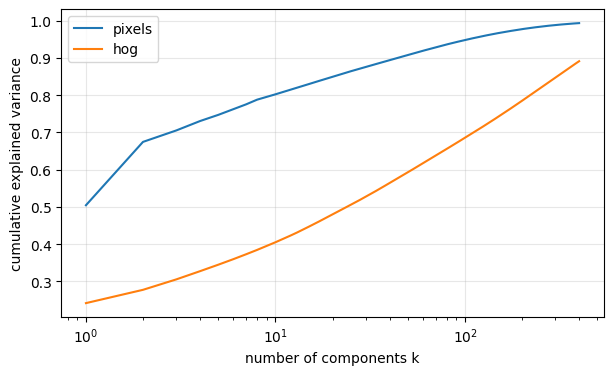

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from porkqc.pca import PCA

pcas = {}
fig, ax = plt.subplots(figsize=(7, 4))
for method in ("pixels", "hog"):
    X_train, _ = feats[method]["train"]
    t = time.perf_counter()
    pcas[method] = PCA(400, whiten=False).fit(X_train)
    cum = np.cumsum(pcas[method].explained_variance_ratio_)
    print(f"{method}: fit {time.perf_counter() - t:.1f} s, cumulative variance:",
          {k: round(float(cum[k - 1]), 3) for k in (10, 50, 100, 400)})
    ax.plot(np.arange(1, 401), cum, label=method)
ax.set(xscale="log", xlabel="number of components k", ylabel="cumulative explained variance")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

##Reconstructing a Pixel Thumbnail

See what PCA keeps and what it throws away; checks that PCA actually works (through being able to rebuild the images) and seeing what the components capture.

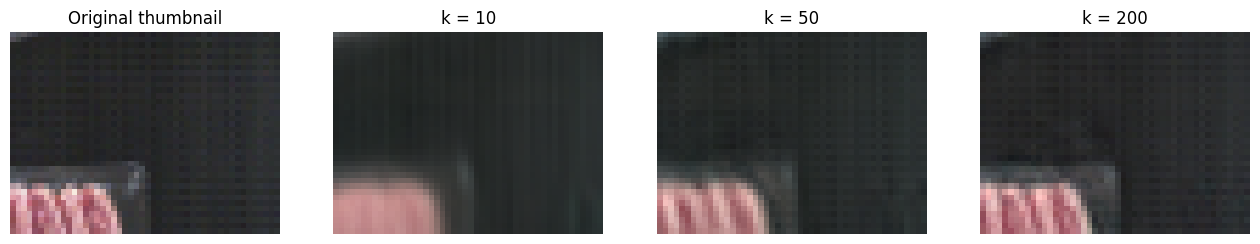

In [7]:
p = pcas["pixels"]
x = feats["pixels"]["valid"][0][[3]]   # one validation image, shape (1, 5184)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
ax[0].imshow(x.reshape(36, 48, 3)); ax[0].set_title("Original thumbnail")
for a, k in zip(ax[1:], (10, 50, 200)):
    z = (x - p.mean_) @ p.components_[:k].T          # compress to k numbers
    rebuilt = z @ p.components_[:k] + p.mean_        # map back to pixels
    a.imshow(np.clip(rebuilt.reshape(36, 48, 3), 0, 1)); a.set_title(f"k = {k}")
for a in ax:
    a.axis("off")
plt.show()

##PCA Tests

In [8]:
%%writefile tests/test_pca.py
"""Verification of PCA: algebraic identities, reference implementation, randomized solver."""

import numpy as np
import pytest
from sklearn.decomposition import PCA as SkPCA

from porkqc.pca import PCA, randomized_svd


@pytest.fixture
def low_rank():
    """60x200 matrix of rank 8 plus small noise, with decaying spectrum."""
    rng = np.random.default_rng(0)
    U = np.linalg.qr(rng.standard_normal((60, 8)))[0]
    V = np.linalg.qr(rng.standard_normal((200, 8)))[0]
    s = 10.0 ** -np.arange(0, 8) * 0.5 + 1
    return U * s * 20 @ V.T + 0.01 * rng.standard_normal((60, 200))


def test_components_are_orthonormal(low_rank):
    p = PCA(10).fit(low_rank)
    np.testing.assert_allclose(p.components_ @ p.components_.T, np.eye(10), atol=1e-12)


def test_full_rank_reconstruction_is_exact(low_rank):
    p = PCA(60, whiten=False).fit(low_rank)
    np.testing.assert_allclose(p.inverse_transform(p.transform(low_rank)), low_rank, atol=1e-10)


def test_whitened_scores_have_unit_variance(low_rank):
    Z = PCA(5, whiten=True).fit(low_rank).transform(low_rank)
    np.testing.assert_allclose(Z.var(axis=0, ddof=1), 1.0, rtol=1e-10)


def test_matches_scikit_learn(low_rank):
    ours = PCA(6, whiten=False).fit(low_rank)
    ref = SkPCA(6, svd_solver="full").fit(low_rank)
    np.testing.assert_allclose(ours.explained_variance_ratio_, ref.explained_variance_ratio_, rtol=1e-10)
    # Components agree up to sign.
    np.testing.assert_allclose(np.abs(ours.components_ @ ref.components_.T), np.eye(6), atol=1e-8)


def test_randomized_solver_recovers_leading_subspace(low_rank):
    full = PCA(8, solver="full").fit(low_rank)
    rand = PCA(8, solver="randomized").fit(low_rank)
    np.testing.assert_allclose(rand.singular_values_, full.singular_values_, rtol=1e-6)
    # Cosines of principal angles between the two subspaces are all ~1.
    cosines = np.linalg.svd(full.components_ @ rand.components_.T, compute_uv=False)
    assert cosines.min() > 1 - 1e-8


def test_randomized_svd_without_power_iterations_is_less_accurate():
    # A slowly decaying spectrum is the hard case the power iterations address.
    rng = np.random.default_rng(1)
    A = rng.standard_normal((300, 300)) @ np.diag(1 / np.sqrt(np.arange(1, 301)))
    exact = np.linalg.svd(A, compute_uv=False)[:10]
    err0 = np.abs(randomized_svd(A, 10, n_power_iter=0)[0] - exact).max()
    err4 = np.abs(randomized_svd(A, 10, n_power_iter=4)[0] - exact).max()
    assert err4 < err0


def test_invalid_inputs_are_rejected(low_rank):
    with pytest.raises(ValueError):
        PCA(0)
    with pytest.raises(ValueError):
        PCA(61).fit(low_rank)
    with pytest.raises(ValueError):
        PCA(2).fit(np.array([[np.nan, 1.0], [1.0, 2.0], [0.0, 0.0]]))
    p = PCA(2).fit(low_rank)
    with pytest.raises(ValueError, match="features"):
        p.transform(low_rank[:, :10])

Writing tests/test_pca.py


##Running Tests

In [9]:
!pytest -q

.........................                                                [100%]
25 passed in 4.36s


##AI Usage Log

In [10]:
%%writefile -a AI_USE_LOG.md
| 2026-10-25 | Claude | Wrote the PCA Module code: src/porkqc/pca.py (PCA via thin SVD and randomized SVD), feature caching, explained-variance and reconstruction plots, and the 7 PCA tests | Ran the plots on the real data and checked the variance values; ran all tests (25 passed), including agreement with scikit-learn; asked Claude to explain parts I did not understand |

Appending to AI_USE_LOG.md


##Commit

In [11]:
!git add pyproject.toml src/porkqc/pca.py tests/test_pca.py notebooks/4_pca.ipynb AI_USE_LOG.md
!git commit -m "Add PCA via thin SVD and randomized SVD, verified against scikit-learn"
!git push {PUSH_URL} feature/pca

[feature/pca 21430d8] Add PCA via thin SVD and randomized SVD, verified against scikit-learn
 5 files changed, 256 insertions(+), 1 deletion(-)
 create mode 100644 notebooks/4_pca.ipynb
 create mode 100644 src/porkqc/pca.py
 create mode 100644 tests/test_pca.py
Enumerating objects: 18, done.
Counting objects: 100% (18/18), done.
Delta compression using up to 2 threads
Compressing objects: 100% (10/10), done.
Writing objects: 100% (11/11), 70.16 KiB | 3.69 MiB/s, done.
Total 11 (delta 6), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (6/6), completed with 6 local objects.
remote: 
remote: Create a pull request for 'feature/pca' on GitHub by visiting:
remote:      https://github.com/chrixxv1/Pork-Tray-Inspection/pull/new/feature/pca
remote: 
To https://github.com/chrixxv1/Pork-Tray-Inspection.git
 * [new branch]      feature/pca -> feature/pca


In [12]:
!git pull {PUSH_URL} main
!git branch -f main HEAD
!git switch main
!git log --oneline -3

remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 928 bytes | 51.00 KiB/s, done.
From https://github.com/chrixxv1/Pork-Tray-Inspection
 * branch            main       -> FETCH_HEAD
Updating 21430d8..3d53068
Fast-forward
M	notebooks/0_setup.ipynb
M	notebooks/1_exploring_data.ipynb
M	notebooks/3_features.ipynb
M	notebooks/4_pca.ipynb
Switched to branch 'main'
Your branch is ahead of 'origin/main' by 16 commits.
  (use "git push" to publish your local commits)
3d53068 (HEAD -> main, feature/pca) Merge pull request #3 from chrixxv1/feature/pca
21430d8 Add PCA via thin SVD and randomized SVD, verified against scikit-learn
cc02bde Update AI_USE_LOG.md
